## 1. Import Library

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error


### 2. LOAD DATASET & PREPROCESSING
Membersihkan data dari nilai 0 (hari libur toko) agar tidak merusak perhitungan error (MAPE) pada model Prophet.

In [ ]:
sheet_name = "aqua_1500ml" 
df = pd.read_excel("dataset/data_clean_ok.xlsx", sheet_name=sheet_name)

df['ds'] = pd.to_datetime(df['ds'])
df = df.sort_values('ds').dropna()

# Mengubah penjualan 0 menjadi NaN
df.loc[df['y'] == 0, 'y'] = np.nan

df.tail() 

,ds,y
1087,2025-12-27,14.0
1088,2025-12-28,16.0
1089,2025-12-29,15.0
1090,2025-12-30,18.0
1091,2025-12-31,12.0


### 3. SPLIT DATA (TRAIN & TEST)
Membagi data uji (Test) secara dinamis tepat 14 hari terakhir sesuai dengan Lead Time (Waktu Tunggu Kedatangan Barang).

In [10]:
lead_time = 14

train_data = df.iloc[:-lead_time].copy()
test_data = df.iloc[-lead_time:].copy()

print("Data Train :", len(train_data), "hari")
print("Data Test  :", len(test_data), "hari")

Data Train : 1078 hari
Data Test  : 14 hari


### 4. TRAINING MODEL PROPHET
Melatih algoritma dengan parameter yang sudah disesuaikan untuk karakteristik fluktuasi produk ini.

In [11]:
skala_terbaik = 0.01 

model = Prophet(
    changepoint_prior_scale=skala_terbaik,
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

model.fit(train_data)

13:51:46 - cmdstanpy - INFO - Chain [1] start processing
13:51:46 - cmdstanpy - INFO - Chain [1] done processing


### 5. EVALUASI MODEL (MAE, RMSE, MAPE)

In [12]:
future = test_data[['ds']].copy()
forecast = model.predict(future)

y_true = test_data['y'].values
y_pred = forecast['yhat'].values

# Masking untuk mengabaikan NaN agar rumus tidak error
mask = ~np.isnan(y_true) & (y_true != 0)

mae = mean_absolute_error(y_true[mask], y_pred[mask])
rmse = np.sqrt(mean_squared_error(y_true[mask], y_pred[mask]))
mape = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f} %")

MAE  : 1.51
RMSE : 1.98
MAPE : 11.48 %


### 6. VISUALISASI HASIL EVALUASI

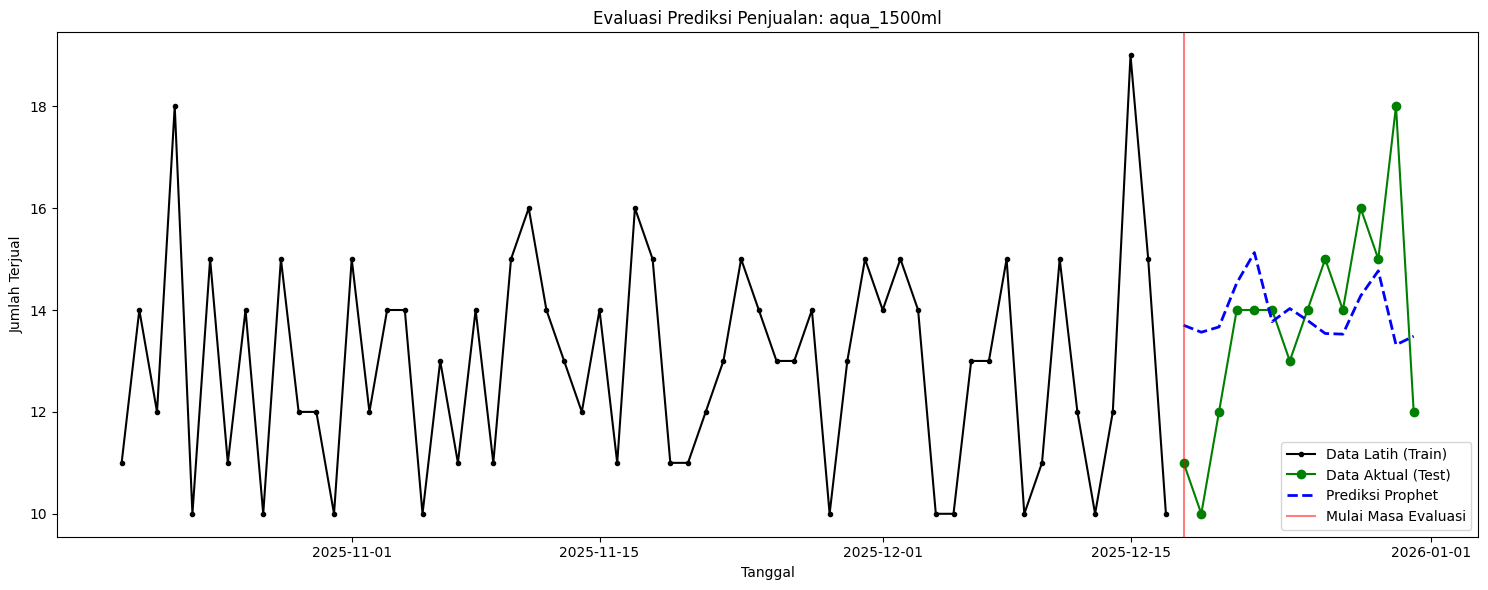

In [13]:
hasil_evaluasi = forecast[['ds', 'yhat']].merge(test_data[['ds', 'y']], on='ds')

plt.figure(figsize=(15, 6))

historical_plot = train_data.iloc[-60:] # Tampilkan 2 bulan
plt.plot(historical_plot['ds'], historical_plot['y'], label='Data Latih (Train)', color='black', marker='.')

plt.plot(hasil_evaluasi['ds'], hasil_evaluasi['y'], label='Data Aktual (Test)', color='green', marker='o')
plt.plot(hasil_evaluasi['ds'], hasil_evaluasi['yhat'], label='Prediksi Prophet', color='blue', linestyle='--', linewidth=2)

plt.axvline(x=test_data['ds'].iloc[0], color='red', linestyle='-', alpha=0.5, label='Mulai Masa Evaluasi')

plt.title(f'Evaluasi Prediksi Penjualan: {sheet_name}')
plt.xlabel('Tanggal')
plt.ylabel('Jumlah Terjual')
plt.legend()
plt.tight_layout()
plt.show()

### 7. FORECAST & PERHITUNGAN REORDER POINT (ROP)
Melatih model dengan keseluruhan data untuk memprediksi kebutuhan stok riil selama Lead Time ke depan.

In [14]:
# Latih ulang dengan df (seluruh data)
final_model = Prophet(
    changepoint_prior_scale=skala_terbaik, 
    yearly_seasonality=True, 
    weekly_seasonality=True
)
final_model.fit(df)

future_14_days = final_model.make_future_dataframe(periods=lead_time, freq='D')
final_forecast = final_model.predict(future_14_days)

# Ambil 14 hari paling akhir
forecast_14 = final_forecast.iloc[-lead_time:]

# --- PERHITUNGAN INVENTARIS ---
kebutuhan_stok = round(forecast_14['yhat'].sum())
safety_stock = round(mae * lead_time)
rekomendasi_pembelian = kebutuhan_stok + safety_stock

print("Kebutuhan stok 14 hari  :", kebutuhan_stok)
print("Safety Stock            :", safety_stock)
print("Rekomendasi pembelian   :", rekomendasi_pembelian)

13:51:46 - cmdstanpy - INFO - Chain [1] start processing
13:51:46 - cmdstanpy - INFO - Chain [1] done processing


Kebutuhan stok 14 hari  : 177
Safety Stock            : 21
Rekomendasi pembelian   : 198
